# JPDA Node Testing

This notebook tests the JPDA node implementation for ROS simulation by loading and analyzing the test_JPDA_node bag file. It compares ground truth data, projected measurements, and the tracking results from the JPDA node.

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime
from collections import defaultdict

# third-party imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

## Configuration and Data Loading

Set up the paths and load the test_JPDA_node rosbag file.

In [3]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/test_JPDA_node.bag')
script_name = "08_JPDA_node"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)
# Log to file and console
logger.info("Notebook started - Testing JPDA Node Implementation")

INFO: Notebook started - Testing JPDA Node Implementation


In [4]:
## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

#################### Topics and message counts: ####################
Topic: /gazebo/model_states
    Message type: TopicInfo(msgtype='gazebo_msgs/msg/ModelStates', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data='# broadcast all model states in world frame\nstring[] name                 # model names\ngeometry_msgs/Pose[] pose     # desired pose in world frame\ngeometry_msgs/Twist[] twist   # desired twist in world frame\n\n================================================================================\nMSG: geometry_msgs/Pose\n# A representation of pose in free space, composed of position and orientation. \nPoint position\nQuaternion orientation\n\n================================================================================\nMSG: geometry_msgs/Point\n# This contains the position of a point in free space\nfloat64 x\nfloat64 y\nfloat64 z\n\n================================================================================\nMSG: geometry_msgs/Quaternion\n# This 

## Data Extraction and Processing

Extract ground truth, projected measurements, and JPDA node tracking results.

In [5]:
## DATA EXTRACTION
topic_data = {}
for i in range(1, 4):
    topics = [
    # Ground truth data
    f"/machine_{i}/target_tracker/MTT/GT/target0",
    f"/machine_{i}/target_tracker/MTT/GT/target2",
    # Projected detections
    f"/machine_{i}/object_detections/projected_to_world",
    # JPDA node results
    f"/machine_{i}/target_tracker/MTT/target_array",
    ]
    # Extract and process data
    for topic in topics:
        if "target_array" in topic:
            # Use special function for target array data
            data = rbu.import_target_array_data(bag_reader, topic)
            topic_data[topic] = data
        else:
            # Use regular function for other topics
            data = rbu.create_df_from_bag(bag_reader, topic)
            topic_data[topic] = data

INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target2' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Importing TargetArray data from topic: /machine_1/target_tracker/MTT/target_array
INFO: Successfully imported 3 tracks from TargetArray messages
INFO: Processing topic: '/machine_2/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_2/target_tracker/MTT/GT/target2' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_2/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Importing TargetArray data from topic

## Analysis of JPDA Node Results

Analyze the tracking results from the JPDA node and compare with ground truth.

In [6]:
## ANALYZE JPDA NODE RESULTS
for i in range(1, 4):
    print(f"\nMachine {i} JPDA Node Results:")
    # Display JPDA node results
    print(f"JPDA Node Results for Machine {i}:")
    jpda_tracks = topic_data[f"/machine_{i}/target_tracker/MTT/target_array"]
    print(f"Number of tracks: {len(jpda_tracks)}")

    # Display track information
    for i, track_df in enumerate(jpda_tracks):
        track_id = track_df['track_id'].iloc[0] if 'track_id' in track_df.columns else i
        track_length = len(track_df)
        time_span = track_df['time'].max() - track_df['time'].min() if len(track_df) > 1 else 0
        print(f"Track {i+1} (ID: {track_id}): {track_length} points, time span: {time_span:.2f}s")


Machine 1 JPDA Node Results:
JPDA Node Results for Machine 1:
Number of tracks: 3
Track 1 (ID: 5): 390 points, time span: 152.25s
Track 2 (ID: 16): 370 points, time span: 144.77s
Track 3 (ID: 19): 334 points, time span: 134.43s

Machine 2 JPDA Node Results:
JPDA Node Results for Machine 2:
Number of tracks: 2
Track 1 (ID: 0): 225 points, time span: 152.42s
Track 2 (ID: 1): 225 points, time span: 152.42s

Machine 3 JPDA Node Results:
JPDA Node Results for Machine 3:
Number of tracks: 2
Track 1 (ID: 2): 497 points, time span: 152.12s
Track 2 (ID: 4): 494 points, time span: 150.50s


## Visualization and Comparison

Create plots comparing ground truth, projected measurements, and JPDA tracking results.

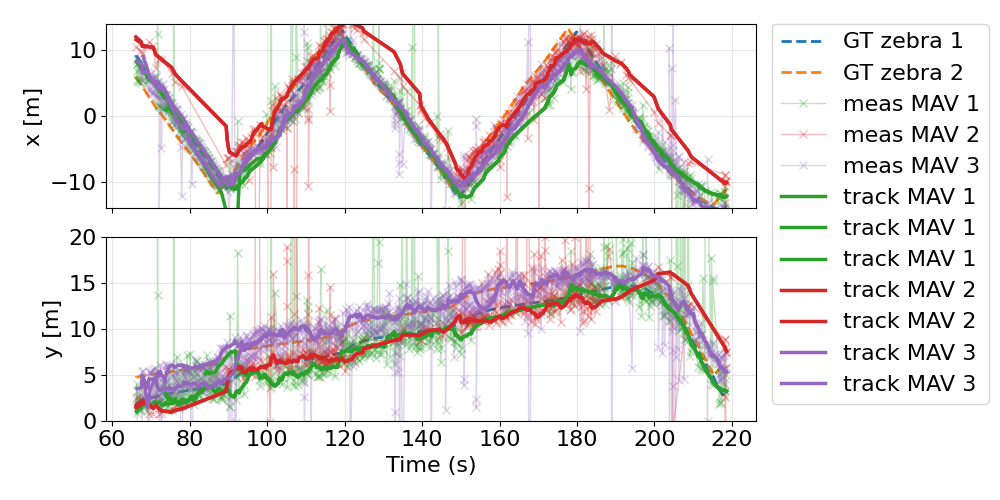

In [7]:
coords = ['x', 'y']

## Create comprehensive comparison plot
# Start with ground truth
fig_comparison = pu.plot_xyz_over_time(
    topic_data[f"/machine_{i}/target_tracker/MTT/GT/target0"], 
    label="GT zebra 1", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)
pu.plot_xyz_over_time(
    topic_data[f"/machine_{i}/target_tracker/MTT/GT/target2"], 
    fig=fig_comparison, 
    label="GT zebra 2", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)

# Add projected measurements
for i in range(1, 4):
    pu.plot_xyz_over_time(
        topic_data[f"/machine_{i}/object_detections/projected_to_world"], 
        fig=fig_comparison, 
        label=f"meas MAV {i}", 
        coords=coords, 
        marker='x', 
        alpha=0.3,
        noisy_limits=True,
    )

# Add JPDA tracking results
tab_colors = ['tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
for i in range(1, 4):
    for track_df in topic_data[f"/machine_{i}/target_tracker/MTT/target_array"]:
        pu.plot_xyz_over_time(
            track_df, 
            fig=fig_comparison, 
            label=f"track MAV {i}", 
            coords=coords, 
            linewidth=2.5,
            color=tab_colors[i % len(tab_colors)],
            noisy_limits=True,
        )

handles, labels = fig_comparison.axes[0].get_legend_handles_labels()
fig_comparison.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_comparison.set_size_inches(10, 5)
fig_comparison.tight_layout(rect=[0, 0, 0.78, 1.0])

fig_comparison.axes[0].set_ylim((-14, 14))
fig_comparison.axes[1].set_ylim((0, 20))

# Set reasonable axis limits
for ax in fig_comparison.axes:
    ax.grid(True, alpha=0.3)

plt.show()

In [8]:
# fig_comparison.savefig(os.path.join(PLOTS_DIR, "jpda_node_comparison.svg"), dpi=600, bbox_inches='tight')

## Individual MAV 1 Analysis

Plot ground truth, MAV 1 projections, and MAV 1 tracks.

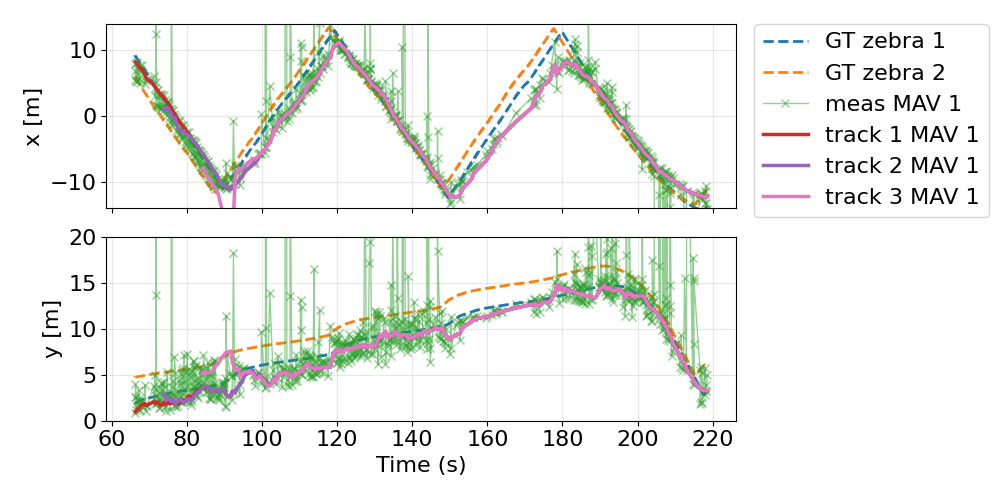

In [9]:
coords = ['x', 'y']

## Create MAV 1 specific plot
fig_mav1 = pu.plot_xyz_over_time(
    topic_data[f"/machine_1/target_tracker/MTT/GT/target0"], 
    label="GT zebra 1", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)
pu.plot_xyz_over_time(
    topic_data[f"/machine_1/target_tracker/MTT/GT/target2"], 
    fig=fig_mav1, 
    label="GT zebra 2", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)

# Add MAV 1 projected measurements
pu.plot_xyz_over_time(
    topic_data[f"/machine_1/object_detections/projected_to_world"], 
    fig=fig_mav1, 
    label="meas MAV 1", 
    coords=coords, 
    marker='x', 
    alpha=0.5,
    noisy_limits=True,
)

# Add MAV 1 tracking results with different colors for each track
track_colors = ['tab:red', 'tab:purple', 'tab:pink', 'tab:olive', 'tab:cyan']
for j, track_df in enumerate(topic_data[f"/machine_1/target_tracker/MTT/target_array"]):
    pu.plot_xyz_over_time(
        track_df, 
        fig=fig_mav1, 
        label=f"track {j+1} MAV 1", 
        coords=coords, 
        linewidth=2.5,
        color=track_colors[j % len(track_colors)],
        noisy_limits=True,
    )

handles, labels = fig_mav1.axes[0].get_legend_handles_labels()
fig_mav1.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_mav1.set_size_inches(10, 5)
fig_mav1.tight_layout(rect=[0, 0, 0.76, 1.0])

fig_mav1.axes[0].set_ylim((-14, 14))
fig_mav1.axes[1].set_ylim((0, 20))

# Set reasonable axis limits
for ax in fig_mav1.axes:
    ax.grid(True, alpha=0.3)

plt.show()

In [10]:
# fig_mav1.savefig(os.path.join(PLOTS_DIR, "jpda_node_mav1.svg"), dpi=600, bbox_inches='tight')

## Individual MAV 2 Analysis

Plot ground truth, MAV 2 projections, and MAV 2 tracks.

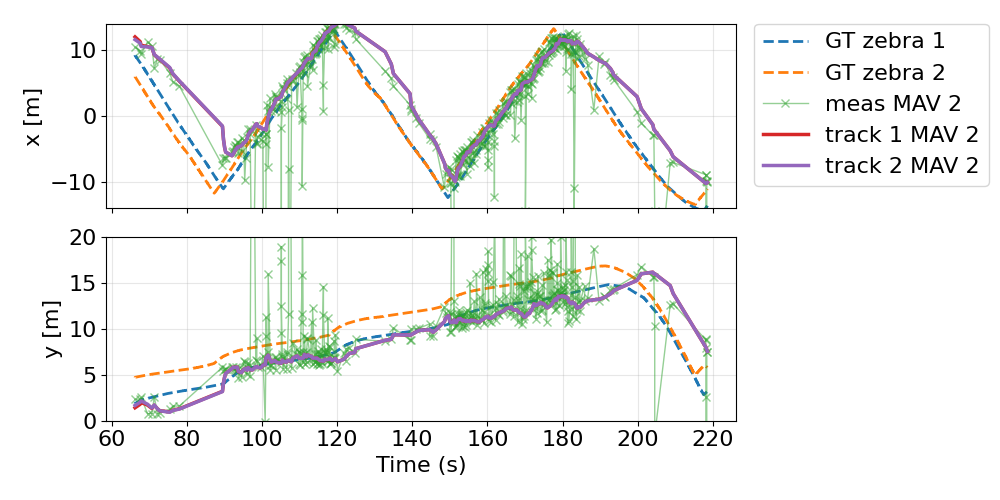

In [11]:
coords = ['x', 'y']

## Create MAV 2 specific plot
fig_mav2 = pu.plot_xyz_over_time(
    topic_data[f"/machine_2/target_tracker/MTT/GT/target0"], 
    label="GT zebra 1", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)
pu.plot_xyz_over_time(
    topic_data[f"/machine_2/target_tracker/MTT/GT/target2"], 
    fig=fig_mav2, 
    label="GT zebra 2", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)

# Add MAV 2 projected measurements
pu.plot_xyz_over_time(
    topic_data[f"/machine_2/object_detections/projected_to_world"], 
    fig=fig_mav2, 
    label="meas MAV 2", 
    coords=coords, 
    marker='x', 
    alpha=0.5,
    noisy_limits=True,
)

# Add MAV 2 tracking results with different colors for each track
track_colors = ['tab:red', 'tab:purple', 'tab:pink', 'tab:olive', 'tab:cyan']
for j, track_df in enumerate(topic_data[f"/machine_2/target_tracker/MTT/target_array"]):
    pu.plot_xyz_over_time(
        track_df, 
        fig=fig_mav2, 
        label=f"track {j+1} MAV 2", 
        coords=coords, 
        linewidth=2.5,
        color=track_colors[j % len(track_colors)],
        noisy_limits=True,
    )

handles, labels = fig_mav2.axes[0].get_legend_handles_labels()
fig_mav2.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_mav2.set_size_inches(10, 5)
fig_mav2.tight_layout(rect=[0, 0, 0.76, 1.0])

fig_mav2.axes[0].set_ylim((-14, 14))
fig_mav2.axes[1].set_ylim((0, 20))

# Set reasonable axis limits
for ax in fig_mav2.axes:
    ax.grid(True, alpha=0.3)

plt.show()

In [12]:
# fig_mav2.savefig(os.path.join(PLOTS_DIR, "jpda_node_mav2.svg"), dpi=600, bbox_inches='tight')

## Individual MAV 3 Analysis

Plot ground truth, MAV 3 projections, and MAV 3 tracks.

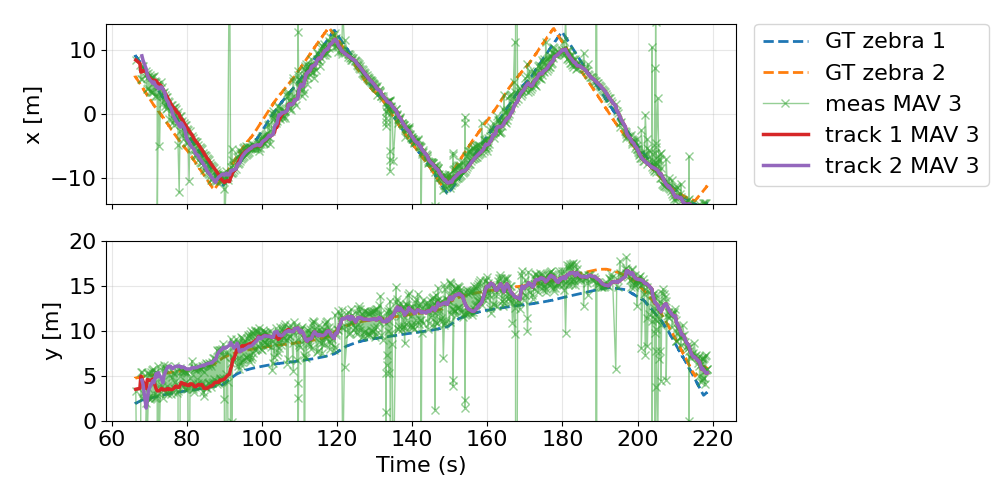

In [13]:
coords = ['x', 'y']

## Create MAV 3 specific plot
fig_mav3 = pu.plot_xyz_over_time(
    topic_data[f"/machine_3/target_tracker/MTT/GT/target0"], 
    label="GT zebra 1", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)
pu.plot_xyz_over_time(
    topic_data[f"/machine_3/target_tracker/MTT/GT/target2"], 
    fig=fig_mav3, 
    label="GT zebra 2", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)

# Add MAV 3 projected measurements
pu.plot_xyz_over_time(
    topic_data[f"/machine_3/object_detections/projected_to_world"], 
    fig=fig_mav3, 
    label="meas MAV 3", 
    coords=coords, 
    marker='x', 
    alpha=0.5,
    noisy_limits=True,
)

# Add MAV 3 tracking results with different colors for each track
track_colors = ['tab:red', 'tab:purple', 'tab:pink', 'tab:olive', 'tab:cyan']
for j, track_df in enumerate(topic_data[f"/machine_3/target_tracker/MTT/target_array"]):
    pu.plot_xyz_over_time(
        track_df, 
        fig=fig_mav3, 
        label=f"track {j+1} MAV 3", 
        coords=coords, 
        linewidth=2.5,
        color=track_colors[j % len(track_colors)],
        noisy_limits=True,
    )

handles, labels = fig_mav3.axes[0].get_legend_handles_labels()
fig_mav3.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_mav3.set_size_inches(10, 5)
fig_mav3.tight_layout(rect=[0, 0, 0.76, 1.0])

fig_mav3.axes[0].set_ylim((-14, 14))
fig_mav3.axes[1].set_ylim((0, 20))

# Set reasonable axis limits
for ax in fig_mav3.axes:
    ax.grid(True, alpha=0.3)

plt.show()

In [14]:
# fig_mav3.savefig(os.path.join(PLOTS_DIR, "jpda_node_mav3.svg"), dpi=600, bbox_inches='tight')

## Combined Selected Tracks Analysis

Plot ground truth and selected tracks: Track 1 from MAV 1 and 2, Track 2 from MAV 3.

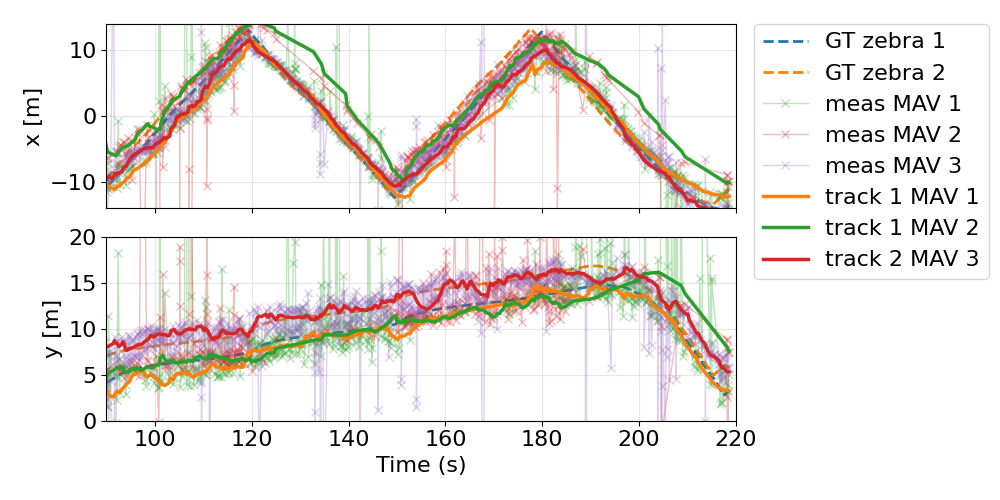

In [15]:
coords = ['x', 'y']

## Create combined selected tracks plot
fig_selected = pu.plot_xyz_over_time(
    topic_data[f"/machine_1/target_tracker/MTT/GT/target0"], 
    label="GT zebra 1", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)
pu.plot_xyz_over_time(
    topic_data[f"/machine_1/target_tracker/MTT/GT/target2"], 
    fig=fig_selected, 
    label="GT zebra 2", 
    linestyle='--', 
    linewidth=2, 
    coords=coords,
    noisy_limits=True,
)

# Add projected measurements from all MAVs
for i in range(1, 4):
    pu.plot_xyz_over_time(
        topic_data[f"/machine_{i}/object_detections/projected_to_world"], 
        fig=fig_selected, 
        label=f"meas MAV {i}", 
        coords=coords, 
        marker='x', 
        alpha=0.3,
        noisy_limits=True,
    )

# Add selected tracks (limit track number per MAV to make the plot more comprehensive)
# MAV 1 - Track 1
if len(topic_data[f"/machine_1/target_tracker/MTT/target_array"]) > 0:
    pu.plot_xyz_over_time(
        topic_data[f"/machine_1/target_tracker/MTT/target_array"][0], 
        fig=fig_selected, 
        label="track 1 MAV 1", 
        coords=coords, 
        linewidth=2.5,
        color='tab:orange',
        noisy_limits=True,
    )

# MAV 2 - Track 1
if len(topic_data[f"/machine_2/target_tracker/MTT/target_array"]) > 0:
    pu.plot_xyz_over_time(
        topic_data[f"/machine_2/target_tracker/MTT/target_array"][0], 
        fig=fig_selected, 
        label="track 1 MAV 2", 
        coords=coords, 
        linewidth=2.5,
        color='tab:green',
        noisy_limits=True,
    )

# MAV 3 - Track 2
if len(topic_data[f"/machine_3/target_tracker/MTT/target_array"]) > 1:
    pu.plot_xyz_over_time(
        topic_data[f"/machine_3/target_tracker/MTT/target_array"][1], 
        fig=fig_selected, 
        label="track 2 MAV 3", 
        coords=coords, 
        linewidth=2.5,
        color='tab:red',
        noisy_limits=True,
    )

handles, labels = fig_selected.axes[0].get_legend_handles_labels()
fig_selected.legend(handles, labels, loc='upper right', bbox_to_anchor=(1, 0.975))
fig_selected.set_size_inches(10, 5)
fig_selected.tight_layout(rect=[0, 0, 0.76, 1.0])

fig_selected.axes[0].set_ylim((-14, 14))
fig_selected.axes[1].set_ylim((0, 20))

# Set reasonable axis limits
for ax in fig_selected.axes:
    ax.grid(True, alpha=0.3)
    ax.set_xlim((90, 220))

plt.show()

In [16]:
# fig_selected.savefig(os.path.join(PLOTS_DIR, "jpda_node_selected_tracks.svg"), dpi=600, bbox_inches='tight')